# Pneumonia Detection Using a Multi-Dimensional Attention Spiking Neural Network



## 1. Environment setup

In [ ]:
import importlib, subprocess, sys

def ensure(pip_name, import_name=None):
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

ensure("snntorch")

import os, time, json, random, copy, shutil
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2
from PIL import Image
from scipy import stats
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import snntorch as snn
from snntorch import surrogate, spikegen
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             roc_curve, precision_score, recall_score, f1_score)
from sklearn.model_selection import train_test_split

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

if os.path.isdir("/kaggle/working"):
    OUT_DIR = "/kaggle/working"
elif os.path.isdir("/content"):
    OUT_DIR = "/content/outputs"
else:
    OUT_DIR = "./outputs"
os.makedirs(OUT_DIR, exist_ok=True)

print("torch", torch.__version__, "| snntorch", snn.__version__, "| opencv", cv2.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (use QUICK mode)")
print("outputs ->", OUT_DIR)

torch 2.14.1+cpu | snntorch 1.0.0 | opencv 5.0.0
device: cpu | CPU only (use QUICK mode)
outputs -> /content/outputs


In [ ]:
QUICK = False
VAL_FROM_TRAIN = False

COMMON = dict(img_size=224, T=12, batch_size=64, lr=1e-3, weight_decay=1e-4,
              eval_passes=3, workers=min(4, os.cpu_count() or 2))
RUNS = {
    "quick": dict(epochs=3, patience=3, train_per_class=100, val_per_class=None, test_per_class=60),
    "full":  dict(epochs=25, patience=6, train_per_class=None, val_per_class=None, test_per_class=None),
}
CFG = {**COMMON, **RUNS["quick" if QUICK else "full"]}
IMG = CFG["img_size"]
CLASSES = ["NORMAL", "PNEUMONIA"]

print(CFG)
if QUICK:
    print("\nQUICK mode: subset of the data and few epochs. These results are NOT final.")

{'img_size': 224, 'T': 12, 'batch_size': 64, 'lr': 0.001, 'weight_decay': 0.0001, 'eval_passes': 3, 'workers': 2, 'epochs': 25, 'patience': 6, 'train_per_class': None, 'val_per_class': None, 'test_per_class': None}


## 2. Dataset loading and exploration



In [ ]:
def find_dataset_root(roots):
    for root in roots:
        if not os.path.isdir(root):
            continue
        for dirpath, dirnames, _ in os.walk(root):
            if "__MACOSX" in dirpath:
                continue
            if all(os.path.isdir(os.path.join(dirpath, s, c))
                   for s in ("train", "val", "test") for c in CLASSES):
                return dirpath
            if dirpath.count(os.sep) - root.count(os.sep) >= 5:
                dirnames.clear()
    return None

DATA_ROOT = find_dataset_root(["/kaggle/input", "/content", "/root/.cache/kagglehub", "/mnt", os.getcwd()])

if DATA_ROOT is None:
    try:
        ensure("kagglehub")
        import kagglehub
        path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
        DATA_ROOT = find_dataset_root([path])
    except Exception as e:
        print("kagglehub download failed:", e)

if DATA_ROOT is None:
    raise FileNotFoundError(
        "Dataset not found. On Kaggle attach 'paultimothymooney/chest-xray-pneumonia'. "
        "On Colab upload/unzip it under /content or provide kaggle.json for kagglehub.")
print("dataset root:", DATA_ROOT)

dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray


       NORMAL  PNEUMONIA
split                   
test      234        390
train    1341       3875
val         8          8
unreadable files: 0


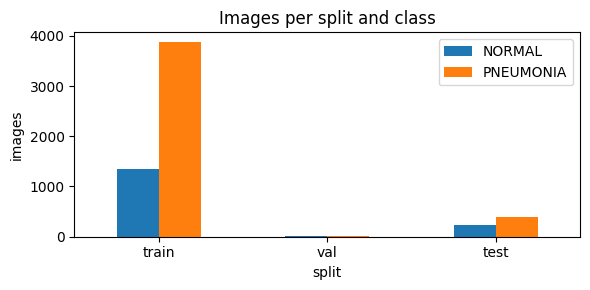

In [ ]:
rows = []
for split in ("train", "val", "test"):
    for label, cls in enumerate(CLASSES):
        folder = os.path.join(DATA_ROOT, split, cls)
        for name in sorted(os.listdir(folder)):
            if name.lower().endswith((".jpeg", ".jpg", ".png")) and not name.startswith("._"):
                rows.append((os.path.join(folder, name), label, split))
df_all = pd.DataFrame(rows, columns=["path", "label", "split"])

counts = df_all.groupby(["split", "label"]).size().unstack(fill_value=0)
counts.columns = CLASSES
print(counts)

def can_open(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

with ThreadPoolExecutor(CFG["workers"]) as ex:
    ok = list(ex.map(can_open, df_all.path))
print("unreadable files:", len(ok) - sum(ok))
df_all = df_all[ok].reset_index(drop=True)

counts.loc[["train", "val", "test"]].plot(kind="bar", figsize=(6, 3), title="Images per split and class")
plt.ylabel("images"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

assert df_all.path.is_unique

In [ ]:

limit = {"train": CFG["train_per_class"], "val": CFG["val_per_class"], "test": CFG["test_per_class"]}
parts = []
for (split, label), g in df_all.groupby(["split", "label"]):
    n = limit[split]
    parts.append(g if n is None else g.sample(min(len(g), n), random_state=SEED))
df_run = pd.concat(parts).reset_index(drop=True)

if VAL_FROM_TRAIN:
    tr = df_run[df_run.split == "train"]
    tr_idx, va_idx = train_test_split(tr.index, test_size=0.15, stratify=tr.label, random_state=SEED)
    df_run.loc[va_idx, "split"] = "val"

print(df_run.groupby(["split", "label"]).size().unstack(fill_value=0).rename(columns=dict(enumerate(CLASSES))))

label  NORMAL  PNEUMONIA
split                   
test      234        390
train    1341       3875
val         8          8


## 3. Image preprocessing (BMF-inspired)



In [ ]:
K_SMALL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
K_LARGE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def load_gray(path):
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

def bmf_preprocess(gray, size=IMG):
    img = cv2.resize(gray, (size, size), interpolation=cv2.INTER_AREA)
    img = cv2.medianBlur(img, 3)
    img = CLAHE.apply(img)
    img = cv2.morphologyEx(img, cv2.MORPH_OPEN, K_SMALL)
    img = cv2.morphologyEx(img, cv2.MORPH_CLOSE, K_SMALL)
    tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, K_LARGE)
    blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, K_LARGE)
    return cv2.subtract(cv2.add(img, tophat), blackhat)

## 4. Lung region extraction


In [ ]:
OUTSIDE_WEIGHT = 0.3

def lung_roi(img):
    h, w = img.shape
    blur = cv2.GaussianBlur(img, (7, 7), 0)
    _, dark = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, k)
    dark = cv2.morphologyEx(dark, cv2.MORPH_CLOSE, k)

    n, labels, st, _ = cv2.connectedComponentsWithStats(dark)
    keep = []
    for i in range(1, n):
        x, y, bw, bh, area = st[i]
        touches_border = x == 0 or y == 0 or x + bw >= w or y + bh >= h
        if area > 0.03 * h * w and not touches_border:
            keep.append((area, i))
    keep = sorted(keep, reverse=True)[:2]

    mask = np.zeros((h, w), np.uint8)
    for _, i in keep:
        cnts, _ = cv2.findContours((labels == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.fillPoly(mask, [cv2.convexHull(np.vstack(cnts))], 1)
    mask = cv2.dilate(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))

    fallback = not (0.12 < mask.mean() < 0.75)
    if fallback:
        mask = np.zeros((h, w), np.uint8)
        cv2.ellipse(mask, (w // 2, int(h * 0.52)), (int(w * 0.40), int(h * 0.40)), 0, 0, 360, 1, -1)
    return mask, fallback

def apply_roi(img, mask):
    weight = mask + (1 - mask) * OUTSIDE_WEIGHT
    return (img * weight).astype(np.uint8)

def prepare_one(path):
    gray = load_gray(path)
    if gray is None:
        return None
    pre = bmf_preprocess(gray)
    mask, fallback = lung_roi(pre)
    return apply_roi(pre, mask), mask, fallback

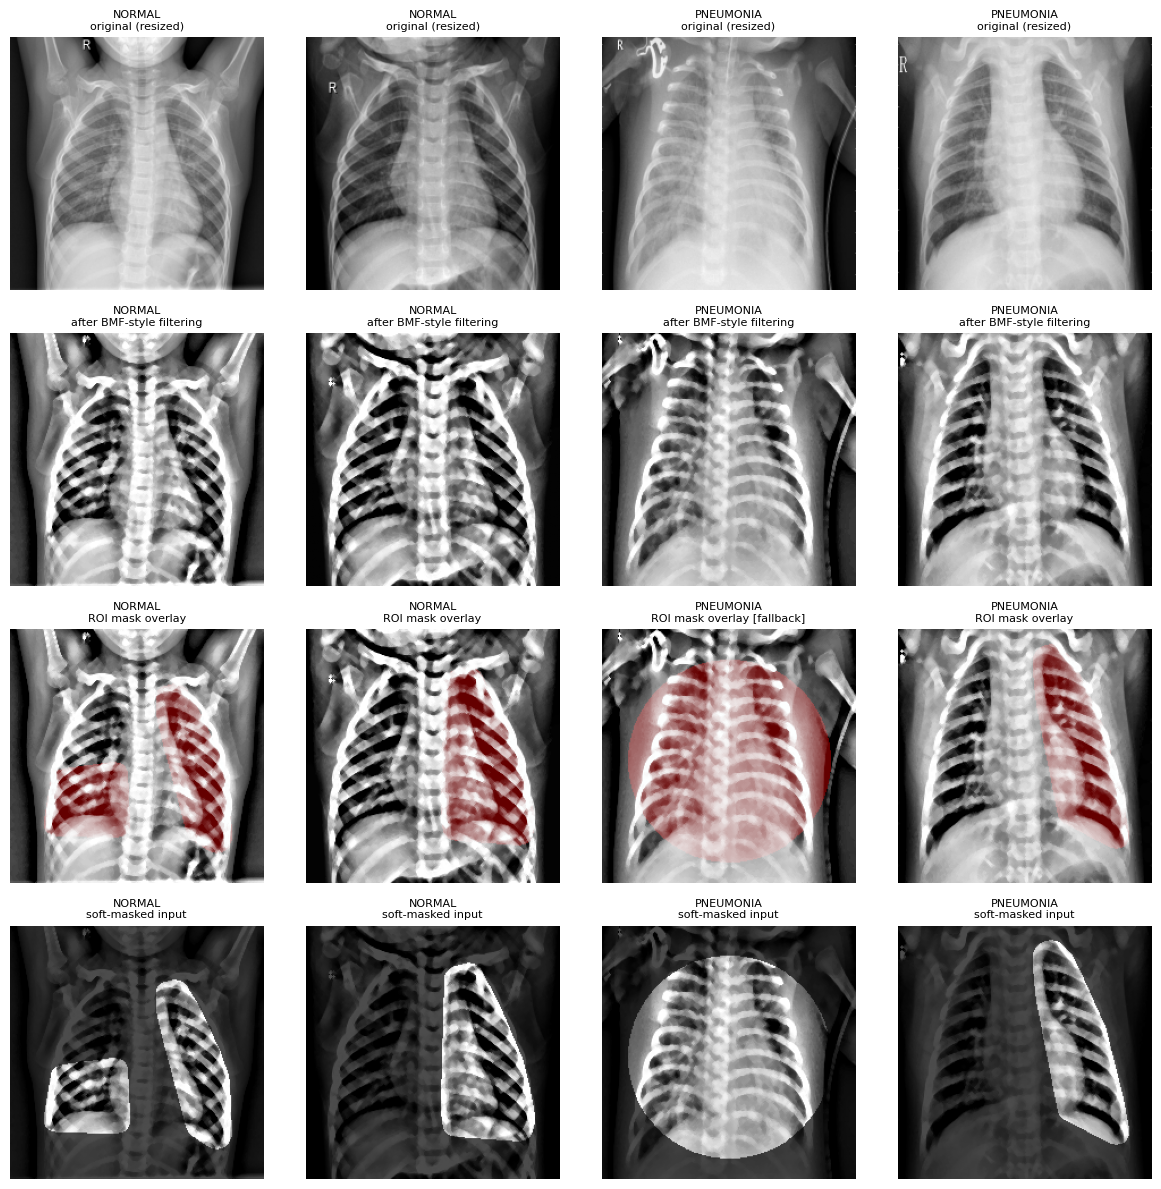

In [ ]:
samples = pd.concat([df_run[(df_run.split == "train") & (df_run.label == c)].head(2) for c in (0, 1)])
fig, axes = plt.subplots(4, len(samples), figsize=(3 * len(samples), 12))
for j, (_, r) in enumerate(samples.iterrows()):
    gray = load_gray(r.path)
    small = cv2.resize(gray, (IMG, IMG), interpolation=cv2.INTER_AREA)
    pre = bmf_preprocess(gray)
    mask, fb = lung_roi(pre)
    overlay = cv2.cvtColor(pre, cv2.COLOR_GRAY2RGB)
    overlay[mask > 0, 0] = np.minimum(255, overlay[mask > 0, 0] * 0.6 + 100)
    for i, (im, title) in enumerate([(small, "original (resized)"), (pre, "after BMF-style filtering"),
                                     (overlay, "ROI mask overlay" + (" [fallback]" if fb else "")),
                                     (apply_roi(pre, mask), "soft-masked input")]):
        axes[i, j].imshow(im, cmap="gray")
        axes[i, j].set_title(f"{CLASSES[r.label]}\n{title}", fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
def build_split(df_split):
    with ThreadPoolExecutor(CFG["workers"]) as ex:
        res = list(tqdm(ex.map(prepare_one, df_split.path), total=len(df_split), desc="preprocessing"))
    good = [i for i, r in enumerate(res) if r is not None]
    imgs = np.stack([res[i][0] for i in good])
    masks = np.stack([res[i][1] for i in good])
    fallback_rate = float(np.mean([res[i][2] for i in good]))
    labels = df_split.label.values[good]
    return imgs, masks, labels, fallback_rate, len(res) - len(good)

DATA = {}
for split in ("train", "val", "test"):
    imgs, masks, labels, fb_rate, bad = build_split(df_run[df_run.split == split])
    DATA[split] = dict(imgs=imgs, masks=masks, labels=labels)
    print(f"{split:5s}: {imgs.shape}, ROI fallback rate {fb_rate:.1%}, unreadable {bad}")

preprocessing:   0%|          | 0/5216 [00:00<?, ?it/s]

train: (5216, 224, 224), ROI fallback rate 49.5%, unreadable 0


preprocessing:   0%|          | 0/16 [00:00<?, ?it/s]

val  : (16, 224, 224), ROI fallback rate 62.5%, unreadable 0


preprocessing:   0%|          | 0/624 [00:00<?, ?it/s]

test : (624, 224, 224), ROI fallback rate 47.3%, unreadable 0


## 5. Feature extraction and fusion



In [ ]:
FEATURE_NAMES = (["mean", "std", "skew", "kurtosis", "p5", "p25", "p50", "p75", "p95", "entropy"]
                 + [f"ring{k}_logE" for k in range(8)]
                 + ["sector0", "sector45", "sector90", "sector135"]
                 + ["spec_centroid", "hf_lf_logratio", "spec_entropy"])

_yy, _xx = np.indices((IMG, IMG))
_R = np.hypot(_yy - IMG // 2, _xx - IMG // 2)
_RMAX = IMG // 2
_RING = np.minimum((_R / _RMAX * 8).astype(int), 8)
_SECTOR = np.minimum((np.mod(np.arctan2(_yy - IMG // 2, _xx - IMG // 2), np.pi) / (np.pi / 4)).astype(int), 3)
_BAND = (_R >= 0.1 * _RMAX) & (_R <= _RMAX)

def stat_features(img, mask):
    px = img[mask > 0].astype(np.float32) / 255.0
    if px.size < 50:
        px = img.ravel().astype(np.float32) / 255.0
    q = np.percentile(px, [5, 25, 50, 75, 95])
    hist = np.histogram(px, bins=32, range=(0, 1))[0].astype(np.float64)
    hist /= hist.sum()
    entropy = -(hist[hist > 0] * np.log2(hist[hist > 0])).sum()
    return [px.mean(), px.std(), stats.skew(px), stats.kurtosis(px), *q, entropy]

def frequency_features(img):
    f = np.fft.fftshift(np.fft.fft2(img.astype(np.float32) / 255.0))
    mag = np.abs(f)
    energy = mag ** 2
    total = energy.sum() + 1e-8
    ring = np.bincount(_RING.ravel(), weights=energy.ravel(), minlength=9)[:8]
    ring = np.log10(ring / total + 1e-10)
    band_total = energy[_BAND].sum() + 1e-8
    sectors = [energy[_BAND & (_SECTOR == k)].sum() / band_total for k in range(4)]
    centroid = (mag * _R).sum() / (mag.sum() + 1e-8) / _RMAX
    hf = energy[_R > 0.5 * _RMAX].sum()
    lf = energy[_R <= 0.5 * _RMAX].sum()
    ratio = np.log10(hf / (lf + 1e-8) + 1e-10)
    pn = energy[_BAND] / band_total
    spec_entropy = -(pn * np.log2(pn + 1e-12)).sum() / np.log2(pn.size)
    return [*ring, *sectors, centroid, ratio, spec_entropy]

def handcrafted(img, mask):
    vec = np.array(stat_features(img, mask) + frequency_features(img), dtype=np.float32)
    return np.nan_to_num(vec, nan=0.0, posinf=0.0, neginf=0.0)

def augment(img, mask, rng):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-10, 10), rng.uniform(0.92, 1.08))
    M[:, 2] += rng.uniform(-0.05, 0.05, 2) * w
    img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    img = np.clip(img.astype(np.float32) * rng.uniform(0.85, 1.15) + rng.uniform(-15, 15), 0, 255).astype(np.uint8)
    return img, mask

assert len(FEATURE_NAMES) == 25
v = handcrafted(DATA["train"]["imgs"][0], DATA["train"]["masks"][0])
print("handcrafted vector shape:", v.shape, "| finite:", bool(np.isfinite(v).all()))

handcrafted vector shape: (25,) | finite: True


In [ ]:

with ThreadPoolExecutor(CFG["workers"]) as ex:
    H_train = np.stack(list(ex.map(lambda a: handcrafted(*a), zip(DATA["train"]["imgs"], DATA["train"]["masks"]))))
HAND_MU = torch.tensor(H_train.mean(0), dtype=torch.float32, device=device)
HAND_SD = torch.tensor(H_train.std(0) + 1e-6, dtype=torch.float32, device=device)

def hand_to_prob(hand, mu=None, sd=None):
    mu = HAND_MU if mu is None else mu
    sd = HAND_SD if sd is None else sd
    return torch.sigmoid((hand - mu) / sd)

class_means = pd.DataFrame(H_train, columns=FEATURE_NAMES).groupby(DATA["train"]["labels"]).mean().T
class_means.columns = CLASSES
class_means["gap (std units)"] = (class_means["PNEUMONIA"] - class_means["NORMAL"]) / H_train.std(0)
print(class_means.round(3).to_string())

                NORMAL  PNEUMONIA  gap (std units)
mean             0.516      0.557            0.601
std              0.308      0.260           -1.114
skew            -0.180     -0.404           -0.624
kurtosis        -1.020     -0.455            0.846
p5               0.003      0.078            0.825
p25              0.270      0.374            0.874
p50              0.544      0.594            0.608
p75              0.763      0.753           -0.154
p95              0.993      0.950           -0.798
entropy          4.785      4.729           -0.378
ring0_logE      -0.050     -0.028            1.295
ring1_logE      -1.130     -1.432           -1.217
ring2_logE      -1.888     -2.117           -1.032
ring3_logE      -2.210     -2.464           -1.057
ring4_logE      -2.508     -2.736           -0.999
ring5_logE      -2.683     -2.897           -0.934
ring6_logE      -2.768     -2.983           -0.923
ring7_logE      -2.798     -3.009           -0.896
sector0          0.200      0.2

In [ ]:
weights = models.MobileNet_V2_Weights.IMAGENET1K_V1
backbone = models.mobilenet_v2(weights=weights).features.to(device).eval()
for p in backbone.parameters():
    p.requires_grad = False

IMN_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMN_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

@torch.no_grad()
def cnn_features(img_u8):
    # img_u8: (B,1,H,W) uint8 -> (B,1280,7,7)
    x = (img_u8.float() / 255.0).repeat(1, 3, 1, 1)
    x = (x - IMN_MEAN) / IMN_STD
    with torch.autocast(device_type=device.type, enabled=USE_AMP):
        f = backbone(x)
    return f.float()

test_feat = cnn_features(torch.from_numpy(DATA["train"]["imgs"][:4])[:, None].to(device))
print("MobileNetV2 feature map:", tuple(test_feat.shape), "| trainable backbone params:",
      sum(p.numel() for p in backbone.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 110MB/s] 


MobileNetV2 feature map: (4, 1280, 7, 7) | trainable backbone params: 0


In [ ]:
class CXRDataset(Dataset):
    def __init__(self, imgs, masks, labels, train):
        self.imgs, self.masks, self.labels, self.train = imgs, masks, labels, train

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        img, mask = self.imgs[i], self.masks[i]
        if self.train:
            rng = np.random.default_rng([torch.initial_seed() % (2 ** 31), i])
            img, mask = augment(img, mask, rng)
        return torch.from_numpy(img)[None], torch.from_numpy(handcrafted(img, mask)), int(self.labels[i])

def make_loader(split, train):
    d = DATA[split]
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(CXRDataset(d["imgs"], d["masks"], d["labels"], train), batch_size=CFG["batch_size"],
                      shuffle=train, drop_last=train, num_workers=CFG["workers"],
                      pin_memory=device.type == "cuda", generator=g)

train_loader, val_loader, test_loader = make_loader("train", True), make_loader("val", False), make_loader("test", False)

n_class = np.bincount(DATA["train"]["labels"], minlength=2)
CLASS_W = torch.tensor(n_class.sum() / (2.0 * n_class), dtype=torch.float32, device=device)
print("train images per class:", dict(zip(CLASSES, n_class)), "| loss weights:", CLASS_W.cpu().numpy().round(3))

train images per class: {'NORMAL': np.int64(1341), 'PNEUMONIA': np.int64(3875)} | loss weights: [1.945 0.673]


## 6. Spike encoding



input probs (1, 25) -> spike tensor (12, 1, 25)


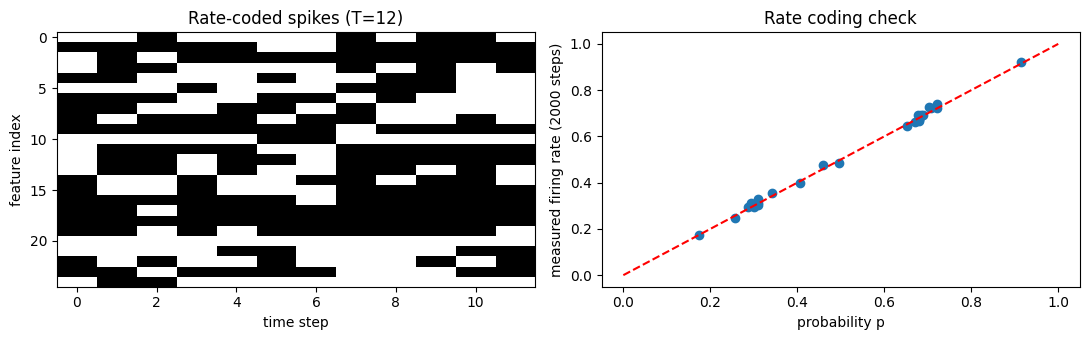

In [ ]:
sample = hand_to_prob(next(iter(test_loader))[1][:1].to(device))
spk = spikegen.rate(sample, num_steps=CFG["T"])
print("input probs", tuple(sample.shape), "-> spike tensor", tuple(spk.shape))

many = spikegen.rate(sample, num_steps=2000)[:, 0, :].mean(0).cpu().numpy()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].imshow(spk[:, 0, :].cpu().numpy().T, aspect="auto", cmap="binary", interpolation="nearest")
ax[0].set_xlabel("time step"); ax[0].set_ylabel("feature index"); ax[0].set_title(f"Rate-coded spikes (T={CFG['T']})")
ax[1].scatter(sample[0].cpu().numpy(), many); ax[1].plot([0, 1], [0, 1], "r--")
ax[1].set_xlabel("probability p"); ax[1].set_ylabel("measured firing rate (2000 steps)"); ax[1].set_title("Rate coding check")
plt.tight_layout(); plt.show()

## 7. Leaky Integrate-and-Fire neuron


max |snnTorch - manual| membrane difference: 3.1582652249007026e-07


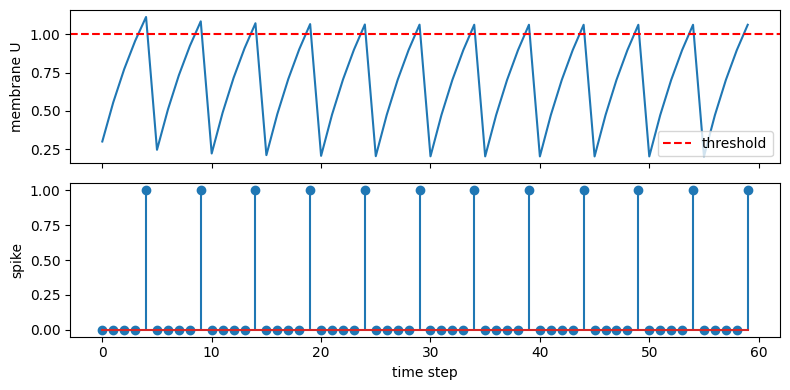

In [ ]:
BETA, THRESH = 0.85, 1.0
spike_grad = surrogate.fast_sigmoid(slope=25)

def make_lif(threshold=THRESH):
    return snn.Leaky(beta=BETA, threshold=threshold, spike_grad=spike_grad,
                     reset_mechanism="subtract", learn_beta=True)

def lif_step(neuron, current, mem):
    if mem is None:
        mem = torch.zeros_like(current)
    return neuron(current, mem)

steps, I = 60, 0.3
neuron = make_lif()
mem, spk_rec, mem_rec = None, [], []
for _ in range(steps):
    s, mem = lif_step(neuron, torch.tensor([I]), mem)
    spk_rec.append(s.item()); mem_rec.append(mem.item())

m, man = 0.0, []
for _ in range(steps):
    reset = float(m > THRESH)
    m = BETA * m + I - reset * THRESH
    man.append(m)
print("max |snnTorch - manual| membrane difference:", float(np.max(np.abs(np.array(mem_rec) - np.array(man)))))

fig, ax = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
ax[0].plot(mem_rec); ax[0].axhline(THRESH, color="r", ls="--", label="threshold"); ax[0].set_ylabel("membrane U"); ax[0].legend()
ax[1].stem(spk_rec); ax[1].set_ylabel("spike"); ax[1].set_xlabel("time step")
plt.tight_layout(); plt.show()

## 8. Multi-dimensional attention


In [ ]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(channels, channels // reduction), nn.ReLU(),
                                 nn.Linear(channels // reduction, channels))

    def forward(self, x):
        w = torch.sigmoid(self.mlp(x.mean((2, 3))) + self.mlp(x.amax((2, 3))))
        return x * w[:, :, None, None], w

class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=3, padding=1)

    def forward(self, x):
        pooled = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], dim=1)
        m = torch.sigmoid(self.conv(pooled))
        return x * m, m

class TemporalAttention(nn.Module):
    def __init__(self, features):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(features, features // 4), nn.Tanh(), nn.Linear(features // 4, 1))

    def forward(self, x):
        w = torch.softmax(self.score(x).squeeze(-1), dim=0)
        return x * (w.unsqueeze(-1) * x.shape[0]), w

c = torch.rand(4, 16, 7, 7)
assert ChannelAttention(16)(c)[0].shape == c.shape and SpatialAttention()(c)[0].shape == c.shape
s = torch.rand(12, 4, 32)
out, w = TemporalAttention(32)(s)
assert out.shape == s.shape and torch.allclose(w.sum(0), torch.ones(4))
print("attention shape checks passed")

attention shape checks passed


## 9. The attention SNN


In [ ]:
class MDASNN(nn.Module):
    def __init__(self, in_ch=1280, hand_dim=25, T=CFG["T"], c_enc=32, c_conv=64, hidden=64,
                 channel_att=True, spatial_att=True, temporal_att=True, dropout=0.3):
        super().__init__()
        self.T = T
        self.encoder = nn.Sequential(nn.Conv2d(in_ch, c_enc, 1, bias=False), nn.BatchNorm2d(c_enc))
        self.conv = nn.Conv2d(c_enc, c_conv, 3, padding=1, bias=False)
        self.conv_bn = nn.BatchNorm2d(c_conv)
        self.lif_conv = make_lif()
        self.channel_att = ChannelAttention(c_conv) if channel_att else None
        self.spatial_att = SpatialAttention() if spatial_att else None

        self.hand_fc = nn.Linear(hand_dim, 64)
        self.hand_bn = nn.BatchNorm1d(64)
        self.lif_hand = make_lif()

        fused = c_conv + 64
        self.temporal_att = TemporalAttention(fused) if temporal_att else None
        self.fc1 = nn.Linear(fused, hidden)
        self.fc1_bn = nn.BatchNorm1d(hidden)
        self.lif1 = make_lif()
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden, 2)
        self.lif_out = make_lif()

    @staticmethod
    def rate_encode(prob):
        return prob + (torch.bernoulli(prob.detach()) - prob).detach()

    def forward(self, feat, hand_prob, record=False):
        T = self.T
        p_vis = torch.sigmoid(self.encoder(feat))
        hand_spk = spikegen.rate(hand_prob, num_steps=T)

        mem_c = mem_h = None
        fused, rec = [], {k: [] for k in ["spk_conv", "spk_hand", "w_ch", "m_sp"]}
        for t in range(T):
            cur = self.conv_bn(self.conv(self.rate_encode(p_vis)))
            spk_c, mem_c = lif_step(self.lif_conv, cur, mem_c)
            if record:
                rec["spk_conv"].append(spk_c)
            if self.channel_att is not None:
                spk_c, w_ch = self.channel_att(spk_c)
                rec["w_ch"].append(w_ch)
            if self.spatial_att is not None:
                spk_c, m_sp = self.spatial_att(spk_c)
                rec["m_sp"].append(m_sp)

            cur_h = self.hand_bn(self.hand_fc(hand_spk[t]))
            spk_h, mem_h = lif_step(self.lif_hand, cur_h, mem_h)
            if record:
                rec["spk_hand"].append(spk_h)
            fused.append(torch.cat([spk_c.mean((2, 3)), spk_h], dim=1))
        fused = torch.stack(fused)

        w_t = None
        if self.temporal_att is not None:
            fused, w_t = self.temporal_att(fused)

        mem1 = mem2 = None
        spk1_rec, spk_out, mem_out = [], [], []
        for t in range(T):
            cur1 = self.fc1_bn(self.fc1(fused[t]))
            spk1, mem1 = lif_step(self.lif1, cur1, mem1)
            spk2, mem2 = lif_step(self.lif_out, self.fc2(self.drop(spk1)), mem2)
            spk1_rec.append(spk1); spk_out.append(spk2); mem_out.append(mem2)
        mem_out = torch.stack(mem_out)
        logits = mem_out.mean(0)

        if not record:
            return logits
        info = {"hand_spk": hand_spk, "spk1": torch.stack(spk1_rec), "spk_out": torch.stack(spk_out),
                "mem_out": mem_out, "w_t": w_t}
        for k, v in rec.items():
            info[k] = torch.stack(v) if len(v) else None
        return logits, info

VARIANTS = {
    "basic_snn":        dict(channel_att=False, spatial_att=False, temporal_att=False),
    "channel_att_snn":  dict(channel_att=True,  spatial_att=False, temporal_att=False),
    "md_attention_snn": dict(channel_att=True,  spatial_att=True,  temporal_att=True),
}
MAIN_VARIANT = "md_attention_snn"

def build_model(flags):
    return MDASNN(**flags).to(device)

print({k: sum(p.numel() for p in build_model(v).parameters()) for k, v in VARIANTS.items()})

{'basic_snn': 69894, 'channel_att_snn': 72022, 'md_attention_snn': 76202}


## 10. Smoke test

In [ ]:
set_seed()
imgs, hand, y = next(iter(train_loader))
feat = cnn_features(imgs.to(device)); hp = hand_to_prob(hand.to(device)); y = y.to(device)
print("images", tuple(imgs.shape), "| handcrafted", tuple(hand.shape), "| CNN features", tuple(feat.shape))

net = build_model(VARIANTS[MAIN_VARIANT]).train()
logits, info = net(feat, hp, record=True)
assert logits.shape == (feat.shape[0], 2)
print("spike tensors:", {k: tuple(v.shape) for k, v in info.items() if v is not None})

loss = F.cross_entropy(logits, y, weight=CLASS_W)
loss.backward()
grads = {n: p.grad for n, p in net.named_parameters()}
assert all(g is not None and torch.isfinite(g).all() for g in grads.values()), "missing or non-finite gradient"
print("gradient norm  encoder:", grads["encoder.0.weight"].norm().item(),
      "| fc2:", grads["fc2.weight"].norm().item(),
      "| lif beta:", grads["lif_hand.beta"].abs().item())
rates = {k: info[k].float().mean().item() for k in ["hand_spk", "spk_conv", "spk_hand", "spk1", "spk_out"]}
print("mean firing rates:", {k: round(v, 3) for k, v in rates.items()})
if any(v == 0 for v in rates.values()):
    print("WARNING: a layer is completely silent")

net = build_model(VARIANTS[MAIN_VARIANT]).train()
opt = torch.optim.Adam(net.parameters(), lr=3e-3)
first = last = None
for step in range(40):
    loss = F.cross_entropy(net(feat, hp), y, weight=CLASS_W)
    opt.zero_grad(); loss.backward(); opt.step()
    first = loss.item() if first is None else first
    last = loss.item()
print(f"loss on a single batch: {first:.3f} -> {last:.3f}")
assert last < first, "loss did not decrease; check the model before training"

images (64, 1, 224, 224) | handcrafted (64, 25) | CNN features (64, 1280, 7, 7)
spike tensors: {'hand_spk': (12, 64, 25), 'spk1': (12, 64, 64), 'spk_out': (12, 64, 2), 'mem_out': (12, 64, 2), 'w_t': (12, 64), 'spk_conv': (12, 64, 64, 7, 7), 'spk_hand': (12, 64, 64), 'w_ch': (12, 64, 64), 'm_sp': (12, 64, 1, 7, 7)}
gradient norm  encoder: 0.01825672574341297 | fc2: 1.072711706161499 | lif beta: 0.0008869123412296176
mean firing rates: {'hand_spk': 0.396, 'spk_conv': 0.19, 'spk_hand': 0.171, 'spk1': 0.18, 'spk_out': 0.004}
loss on a single batch: 0.710 -> 0.001


## 11. Training


In [ ]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    for imgs, hand, y in loader:
        feat = cnn_features(imgs.to(device, non_blocking=True))
        hp = hand_to_prob(hand.to(device))
        y = y.to(device)
        with torch.set_grad_enabled(training):
            logits = model(feat, hp)
            loss = F.cross_entropy(logits, y, weight=CLASS_W)
        if training:
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

def train_variant(name, flags):
    set_seed()
    model = build_model(flags)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"])
    history, best_loss, best_state, bad_epochs = [], float("inf"), None, 0
    start = time.time()
    for epoch in range(1, CFG["epochs"] + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        scheduler.step()
        history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc))
        print(f"[{name}] epoch {epoch:2d}  train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f}")
        if va_loss < best_loss:
            best_loss, bad_epochs = va_loss, 0
            best_state = copy.deepcopy(model.state_dict())
            torch.save({"state": best_state, "flags": flags, "T": CFG["T"], "classes": CLASSES,
                        "hand_mu": HAND_MU.cpu(), "hand_sd": HAND_SD.cpu(), "epoch": epoch},
                       os.path.join(OUT_DIR, f"{name}.pt"))
        else:
            bad_epochs += 1
            if bad_epochs >= CFG["patience"]:
                print(f"[{name}] early stopping at epoch {epoch}")
                break
    model.load_state_dict(best_state)
    minutes = (time.time() - start) / 60
    print(f"[{name}] finished in {minutes:.1f} min, best val loss {best_loss:.4f}")
    return model, pd.DataFrame(history), minutes

In [ ]:
trained, histories, train_minutes = {}, {}, {}
order = [MAIN_VARIANT] + [v for v in VARIANTS if v != MAIN_VARIANT]
for name in order:
    trained[name], histories[name], train_minutes[name] = train_variant(name, VARIANTS[name])
    histories[name].to_csv(os.path.join(OUT_DIR, f"history_{name}.csv"), index=False)

[md_attention_snn] epoch  1  train loss 0.2810 acc 0.865 | val loss 0.2028 acc 0.938
[md_attention_snn] epoch  2  train loss 0.1845 acc 0.927 | val loss 0.2174 acc 1.000
[md_attention_snn] epoch  3  train loss 0.1770 acc 0.930 | val loss 0.1155 acc 1.000
[md_attention_snn] epoch  4  train loss 0.1518 acc 0.939 | val loss 0.2349 acc 1.000
[md_attention_snn] epoch  5  train loss 0.1495 acc 0.941 | val loss 0.1901 acc 0.938
[md_attention_snn] epoch  6  train loss 0.1400 acc 0.942 | val loss 0.2468 acc 0.938
[md_attention_snn] epoch  7  train loss 0.1412 acc 0.942 | val loss 0.5408 acc 0.750
[md_attention_snn] epoch  8  train loss 0.1327 acc 0.946 | val loss 0.4148 acc 0.938
[md_attention_snn] epoch  9  train loss 0.1308 acc 0.949 | val loss 0.2885 acc 0.938
[md_attention_snn] early stopping at epoch 9
[md_attention_snn] finished in 63.1 min, best val loss 0.1155
[basic_snn] epoch  1  train loss 0.2649 acc 0.883 | val loss 0.3446 acc 0.875
[basic_snn] epoch  2  train loss 0.1794 acc 0.930 

## 12. Evaluation on the untouched test set

The test loader was never used for training, early stopping or model selection. Rate coding is random, so predictions are averaged over `eval_passes` stochastic passes with a fixed seed.

In [ ]:
@torch.no_grad()
def predict_loader(model, loader, passes=CFG["eval_passes"]):
    model.eval()
    torch.manual_seed(SEED)
    probs, labels = [], []
    for imgs, hand, y in loader:
        feat = cnn_features(imgs.to(device))
        hp = hand_to_prob(hand.to(device))
        p = sum(torch.softmax(model(feat, hp), 1)[:, 1] for _ in range(passes)) / passes
        probs.append(p.cpu()); labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

def compute_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(accuracy=(tp + tn) / len(y), precision=precision_score(y, pred, zero_division=0),
                recall_sensitivity=recall_score(y, pred), specificity=tn / (tn + fp),
                f1=f1_score(y, pred), roc_auc=roc_auc_score(y, p), tn=tn, fp=fp, fn=fn, tp=tp)

test_out, metrics = {}, {}
for name, model in trained.items():
    test_out[name] = predict_loader(model, test_loader)
    metrics[name] = compute_metrics(test_out[name][1], test_out[name][0])
results = pd.DataFrame(metrics).T
results["train_minutes"] = pd.Series(train_minutes)
results.to_csv(os.path.join(OUT_DIR, "test_metrics.csv"))
print(results.round(4).to_string())
if QUICK:
    print("\nQUICK mode result: subset of data, very short training. Not a final result.")

                  accuracy  precision  recall_sensitivity  specificity      f1  roc_auc     tn    fp    fn     tp  train_minutes
md_attention_snn    0.8622     0.8602              0.9308       0.7479  0.8941   0.9303  175.0  59.0  27.0  363.0        63.1100
basic_snn           0.8333     0.8004              0.9769       0.5940  0.8799   0.9361  139.0  95.0   9.0  381.0        60.0941
channel_att_snn     0.8670     0.8513              0.9538       0.7222  0.8996   0.9297  169.0  65.0  18.0  372.0        54.8080


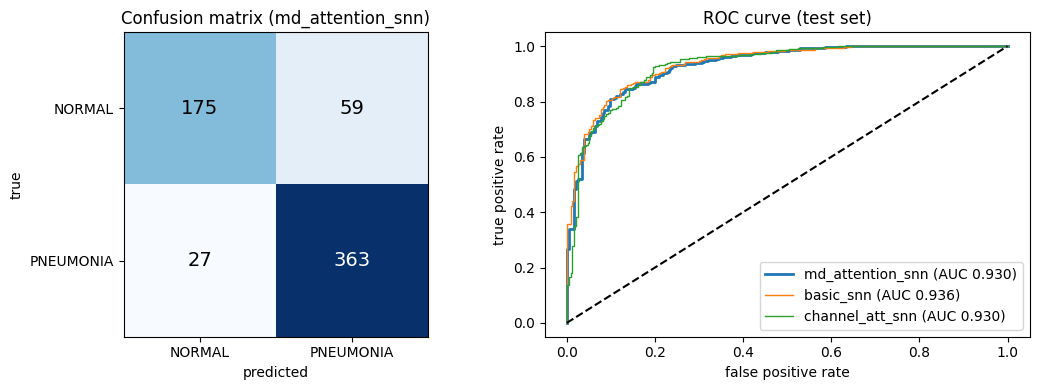

              precision    recall  f1-score   support

      NORMAL     0.8663    0.7479    0.8028       234
   PNEUMONIA     0.8602    0.9308    0.8941       390

    accuracy                         0.8622       624
   macro avg     0.8633    0.8393    0.8484       624
weighted avg     0.8625    0.8622    0.8598       624



In [ ]:
p_main, y_true = test_out[MAIN_VARIANT]
pred_main = (p_main >= 0.5).astype(int)
cm = confusion_matrix(y_true, pred_main, labels=[0, 1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks([0, 1], CLASSES); ax[0].set_yticks([0, 1], CLASSES)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title(f"Confusion matrix ({MAIN_VARIANT})")
for name in trained:
    fpr, tpr, _ = roc_curve(test_out[name][1], test_out[name][0])
    ax[1].plot(fpr, tpr, lw=2 if name == MAIN_VARIANT else 1, label=f"{name} (AUC {metrics[name]['roc_auc']:.3f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
ax[1].set_title("ROC curve (test set)"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_roc.png"), dpi=150); plt.show()

print(classification_report(y_true, pred_main, target_names=CLASSES, digits=4))

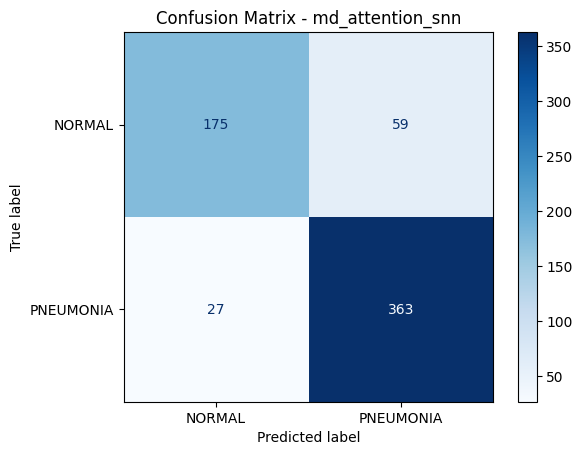

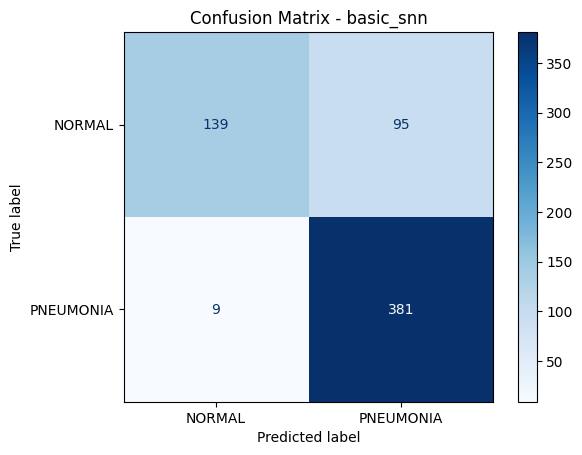

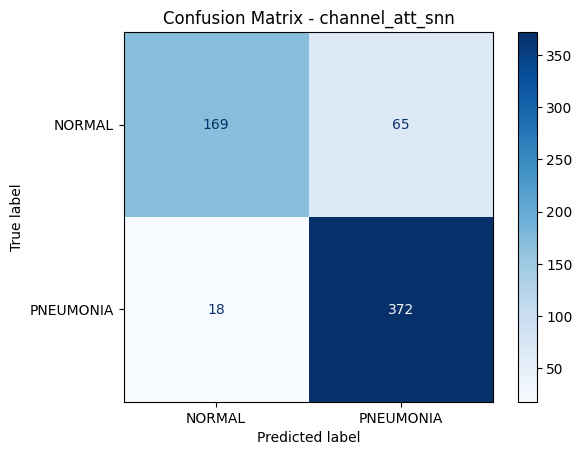

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name in trained:

    probabilities = test_out[name][0]
    actual_labels = test_out[name][1]

    predicted_labels = (probabilities >= 0.5).astype(int)

    cm = confusion_matrix(
        actual_labels,
        predicted_labels,
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASSES
    )

    display.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()


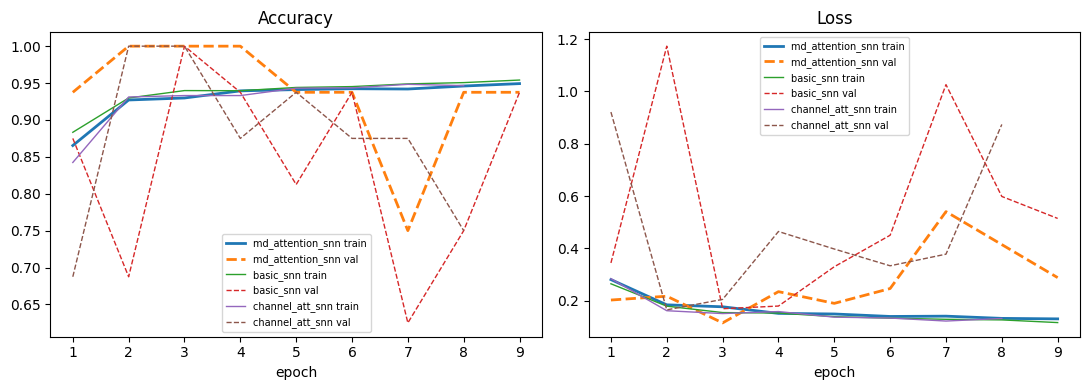

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, h in histories.items():
    lw = 2 if name == MAIN_VARIANT else 1
    ax[0].plot(h.epoch, h.train_acc, lw=lw, label=f"{name} train"); ax[0].plot(h.epoch, h.val_acc, "--", lw=lw, label=f"{name} val")
    ax[1].plot(h.epoch, h.train_loss, lw=lw, label=f"{name} train"); ax[1].plot(h.epoch, h.val_loss, "--", lw=lw, label=f"{name} val")
ax[0].set_title("Accuracy"); ax[1].set_title("Loss")
for a in ax:
    a.set_xlabel("epoch"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=150); plt.show()

## 13. Spike activity, attention and explainability

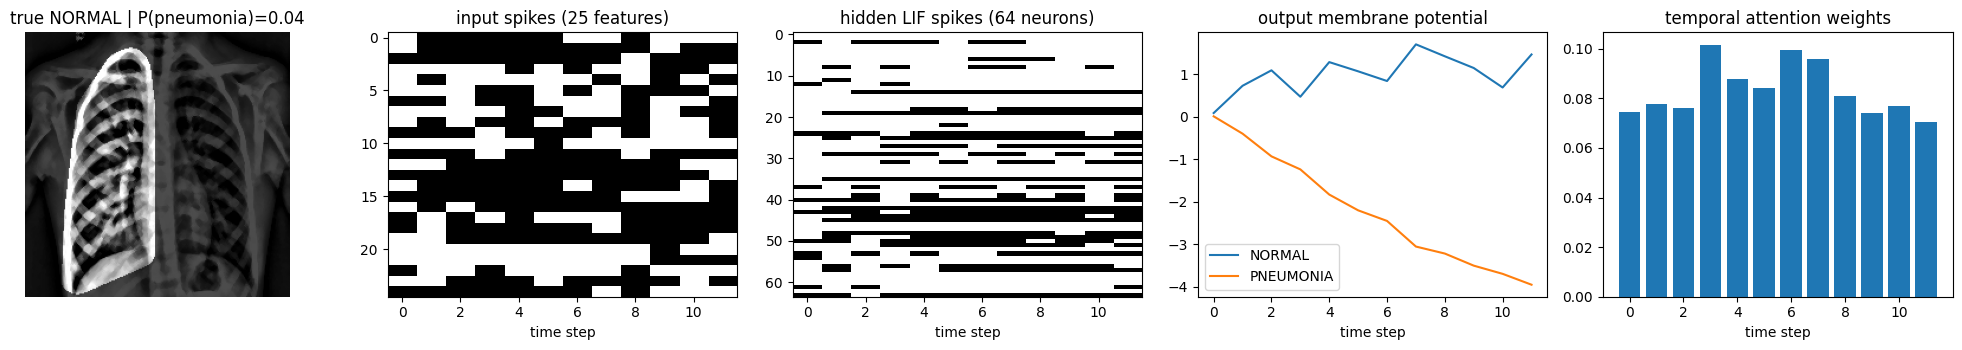

firing rates: {'hand_spk': 0.58, 'spk_conv': 0.329, 'spk_hand': 0.22, 'spk1': 0.31, 'spk_out': 0.292}


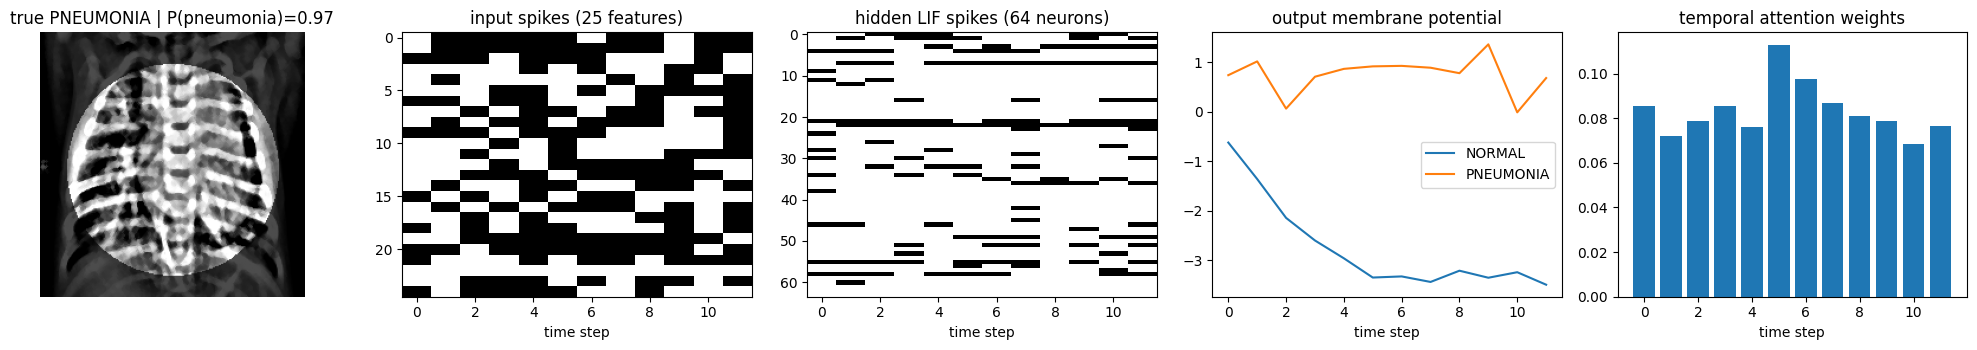

firing rates: {'hand_spk': 0.527, 'spk_conv': 0.214, 'spk_hand': 0.156, 'spk1': 0.167, 'spk_out': 0.083}


In [ ]:
@torch.no_grad()
def get_sample(split, label):
    d = DATA[split]
    i = int(np.where(d["labels"] == label)[0][0])
    img, mask = d["imgs"][i], d["masks"][i]
    return img, mask, torch.from_numpy(handcrafted(img, mask))[None]

def visualize_spikes(model, label):
    img, mask, hand = get_sample("test", label)
    model.eval(); torch.manual_seed(SEED)
    with torch.no_grad():
        logits, info = model(cnn_features(torch.from_numpy(img)[None, None].to(device)),
                             hand_to_prob(hand.to(device)), record=True)
    prob = torch.softmax(logits, 1)[0, 1].item()
    fig, ax = plt.subplots(1, 5, figsize=(20, 3.6))
    ax[0].imshow(img, cmap="gray"); ax[0].set_title(f"true {CLASSES[label]} | P(pneumonia)={prob:.2f}"); ax[0].axis("off")
    ax[1].imshow(info["hand_spk"][:, 0].cpu().numpy().T, aspect="auto", cmap="binary", interpolation="nearest")
    ax[1].set_title("input spikes (25 features)"); ax[1].set_xlabel("time step")
    ax[2].imshow(info["spk1"][:, 0].cpu().numpy().T, aspect="auto", cmap="binary", interpolation="nearest")
    ax[2].set_title("hidden LIF spikes (64 neurons)"); ax[2].set_xlabel("time step")
    mem = info["mem_out"][:, 0].cpu().numpy()
    for k in range(2):
        ax[3].plot(mem[:, k], label=CLASSES[k])
    spk_t, spk_k = np.where(info["spk_out"][:, 0].cpu().numpy() > 0)
    ax[3].set_title("output membrane potential"); ax[3].set_xlabel("time step"); ax[3].legend()
    if info["w_t"] is not None:
        ax[4].bar(range(CFG["T"]), info["w_t"][:, 0].cpu().numpy()); ax[4].set_title("temporal attention weights")
        ax[4].set_xlabel("time step")
    else:
        ax[4].axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"spikes_{CLASSES[label].lower()}.png"), dpi=150); plt.show()
    print("firing rates:", {k: round(info[k].float().mean().item(), 3) for k in ["hand_spk", "spk_conv", "spk_hand", "spk1", "spk_out"]})

main_model = trained[MAIN_VARIANT]
for lab in (0, 1):
    visualize_spikes(main_model, lab)

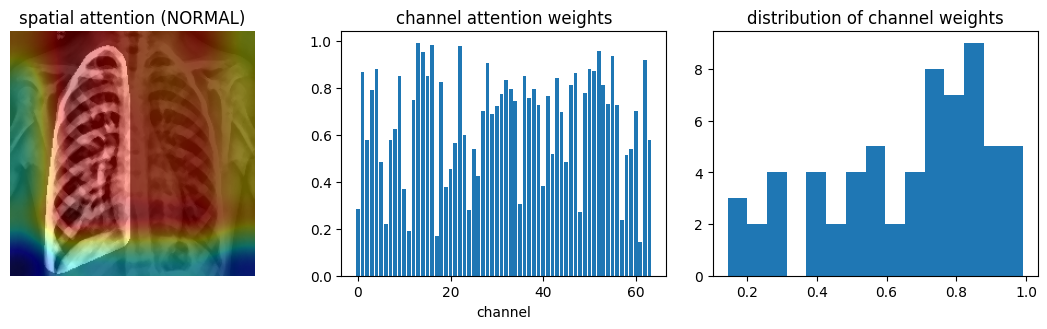

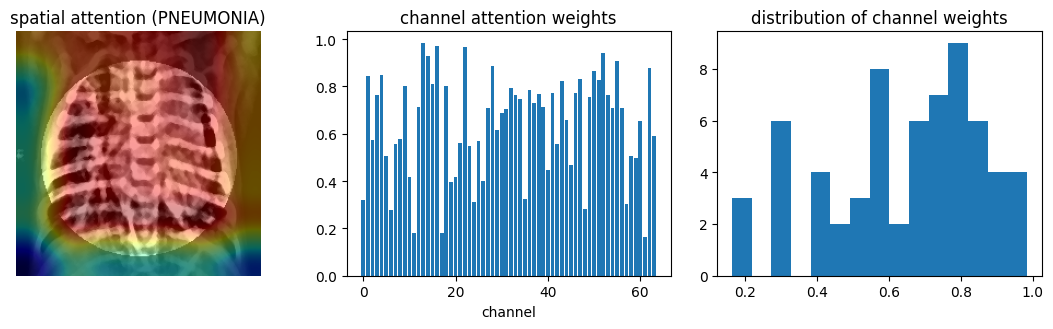

In [ ]:
def show_spatial_attention(model, label):
    img, mask, hand = get_sample("test", label)
    model.eval(); torch.manual_seed(SEED)
    with torch.no_grad():
        _, info = model(cnn_features(torch.from_numpy(img)[None, None].to(device)), hand_to_prob(hand.to(device)), record=True)
    m = info["m_sp"][:, 0, 0].mean(0).cpu().numpy()
    m = cv2.resize(m, (IMG, IMG), interpolation=cv2.INTER_CUBIC)
    w_ch = info["w_ch"][:, 0].mean(0).cpu().numpy()
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
    ax[0].imshow(img, cmap="gray"); ax[0].imshow(m, cmap="jet", alpha=0.4); ax[0].set_title(f"spatial attention ({CLASSES[label]})"); ax[0].axis("off")
    ax[1].bar(range(len(w_ch)), w_ch); ax[1].set_title("channel attention weights"); ax[1].set_xlabel("channel")
    ax[2].hist(w_ch, bins=15); ax[2].set_title("distribution of channel weights")
    plt.tight_layout(); plt.show()

for lab in (0, 1):
    show_spatial_attention(main_model, lab)

### Grad-CAM on the MobileNetV2 feature map



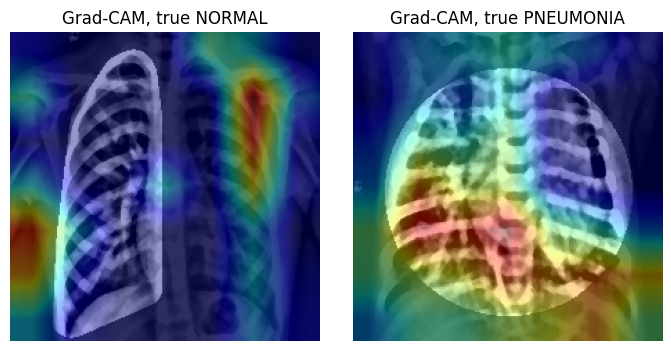

In [ ]:
def gradcam(model, img, mask):
    model.eval(); torch.manual_seed(SEED)
    x = torch.from_numpy(img)[None, None].to(device)
    hp = hand_to_prob(torch.from_numpy(handcrafted(img, mask))[None].to(device))
    feat = cnn_features(x).clone().requires_grad_(True)
    logits = model(feat, hp)
    model.zero_grad()
    logits[0, 1].backward()
    w = feat.grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * feat).sum(1, keepdim=True)).detach()
    cam = F.interpolate(cam, size=(IMG, IMG), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    return cam / (cam.max() + 1e-8)

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
for lab in (0, 1):
    img, mask, _ = get_sample("test", lab)
    ax[lab].imshow(img, cmap="gray"); ax[lab].imshow(gradcam(main_model, img, mask), cmap="jet", alpha=0.4)
    ax[lab].set_title(f"Grad-CAM, true {CLASSES[lab]}"); ax[lab].axis("off")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "gradcam.png"), dpi=150); plt.show()

## 14. Predicting a single X-ray

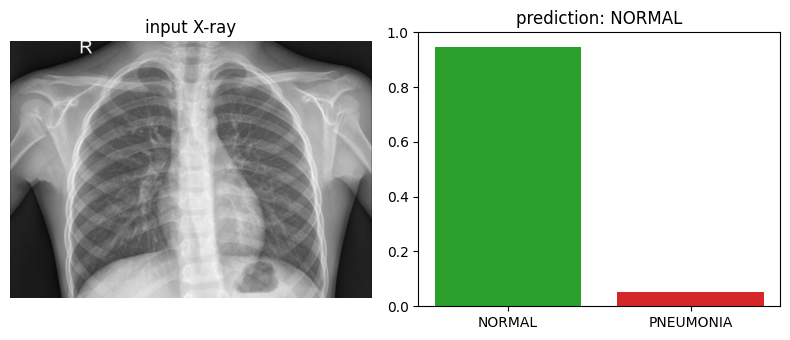

true: NORMAL -> ('NORMAL', {'NORMAL': 0.9480810165405273, 'PNEUMONIA': 0.05191899463534355})


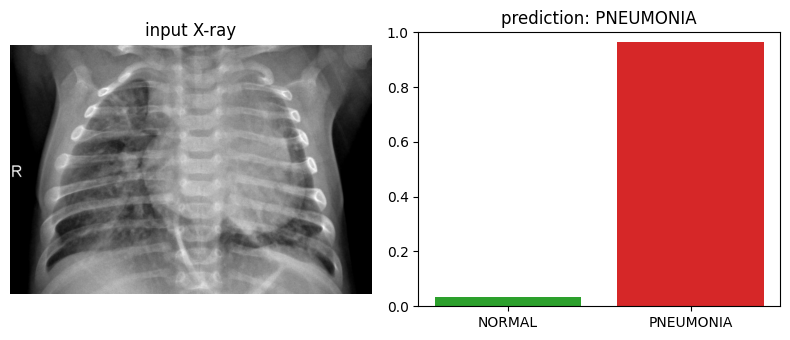

true: PNEUMONIA -> ('PNEUMONIA', {'NORMAL': 0.03465336188673973, 'PNEUMONIA': 0.9653466939926147})
Educational project only: not a medical device and not for clinical use.


In [ ]:
def load_model(path):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model = MDASNN(T=ckpt["T"], **ckpt["flags"]).to(device)
    model.load_state_dict(ckpt["state"])
    return model.eval(), ckpt["hand_mu"].to(device), ckpt["hand_sd"].to(device)

@torch.no_grad()
def predict_pneumonia(image_path, checkpoint=None, passes=10, show=True):
    checkpoint = checkpoint or os.path.join(OUT_DIR, f"{MAIN_VARIANT}.pt")
    model, mu, sd = load_model(checkpoint)
    prepared = prepare_one(image_path)
    if prepared is None:
        raise ValueError(f"could not read image: {image_path}")
    img, mask, _ = prepared
    hp = hand_to_prob(torch.from_numpy(handcrafted(img, mask))[None].to(device), mu, sd)
    feat = cnn_features(torch.from_numpy(img)[None, None].to(device))
    torch.manual_seed(SEED)
    probs = sum(torch.softmax(model(feat, hp), 1)[0] for _ in range(passes)) / passes
    result = {CLASSES[k]: float(probs[k]) for k in range(2)}
    label = CLASSES[int(probs.argmax())]
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
        ax[0].imshow(load_gray(image_path), cmap="gray"); ax[0].set_title("input X-ray"); ax[0].axis("off")
        ax[1].bar(CLASSES, [result[c] for c in CLASSES], color=["tab:green", "tab:red"]); ax[1].set_ylim(0, 1)
        ax[1].set_title(f"prediction: {label}")
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "sample_prediction.png"), dpi=150); plt.show()
    return label, result

for lab in (0, 1):
    path = df_all[(df_all.split == "test") & (df_all.label == lab)].path.iloc[0]
    print("true:", CLASSES[lab], "->", predict_pneumonia(path))
print("Educational project only: not a medical device and not for clinical use.")

## 15. Checkpoint reload test and export

In [ ]:

reloaded, mu, sd = load_model(os.path.join(OUT_DIR, f"{MAIN_VARIANT}.pt"))
imgs, hand, _ = next(iter(test_loader))
feat = cnn_features(imgs.to(device)); hp = hand_to_prob(hand.to(device))
with torch.no_grad():
    torch.manual_seed(0); a = main_model.eval()(feat, hp)
    torch.manual_seed(0); b = reloaded(feat, hp)
print("reload check, max |difference|:", (a - b).abs().max().item())
assert torch.allclose(a, b, atol=1e-5)

summary = dict(config=CFG, quick_mode=QUICK, main_variant=MAIN_VARIANT, test_metrics=metrics, train_minutes=train_minutes)
with open(os.path.join(OUT_DIR, "run_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)
print(sorted(os.listdir(OUT_DIR)))

try:
    from google.colab import files
    shutil.make_archive("/content/pneumonia_snn_outputs", "zip", OUT_DIR)
    files.download("/content/pneumonia_snn_outputs.zip")
except ImportError:
    pass

reload check, max |difference|: 0.0
['basic_snn.pt', 'channel_att_snn.pt', 'confusion_roc.png', 'gradcam.png', 'history_basic_snn.csv', 'history_channel_att_snn.csv', 'history_md_attention_snn.csv', 'md_attention_snn.pt', 'run_summary.json', 'sample_prediction.png', 'spikes_normal.png', 'spikes_pneumonia.png', 'test_metrics.csv', 'training_curves.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>